# Feature Normalization Analysis: Social Network Ads

This notebook provides a step-by-step analysis of **min–max normalization** for the Social Network Ads dataset. It covers data inspection, the purpose of normalization, a train/test-safe workflow, visual comparisons, checks, and practical interpretation.

**Normalization here means rescaling numeric features to a common interval**, usually $[0,1]$. It does not make a feature normally distributed. We will normalize `Age` and `EstimatedSalary`; `User ID` is an identifier and `Purchased` is the outcome, so neither belongs in the feature scaler.

> Run the cells from top to bottom. The source CSV is expected beside this notebook.


## 1. Import libraries and load the data

We use pandas for data handling, NumPy for numerical checks, Matplotlib/Seaborn for plots, and scikit-learn for preprocessing and splitting. If an import is unavailable in your environment, install the corresponding package before continuing.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid", palette="Set2")

DATA_PATH = Path("Social_Network_Ads.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}. Keep the CSV beside this notebook.")

df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 400 | Columns: 5


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


## 2. Understand the columns and data quality

`User ID` identifies a person; its magnitude has no useful distance relationship. `Gender` is categorical. `Age` and `EstimatedSalary` are numeric inputs. `Purchased` is a binary outcome (0 = did not purchase, 1 = purchased).

We inspect types, missing values, duplicate rows, and summary statistics before transforming anything. Min–max scaling depends on observed minima and maxima, so extreme values can compress most observations into a narrow band.

In [2]:
print("Column types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
print("Summary statistics:")
display(df.describe(include="all").T)

Column types:


,dtype
User ID,int64
Gender,object
Age,int64
EstimatedSalary,int64
Purchased,int64


Missing values:


,missing_count
User ID,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


Duplicate rows: 0
Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User ID,400.0,NaN,NaN,NaN,15691539.7575,71658.321581,15566689.0,15626763.75,15694341.5,15750363.0,15815236.0
Gender,400,2,Female,204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,400.0,NaN,NaN,NaN,37.655,10.482877,18.0,29.75,37.0,46.0,60.0
EstimatedSalary,400.0,NaN,NaN,NaN,69742.5,34096.960282,15000.0,43000.0,70000.0,88000.0,150000.0
Purchased,400.0,NaN,NaN,NaN,0.3575,0.479864,0.0,0.0,0.0,1.0,1.0


In [3]:
expected = {"User ID", "Gender", "Age", "EstimatedSalary", "Purchased"}
missing_columns = expected - set(df.columns)
if missing_columns:
    raise ValueError(f"Expected columns are missing: {sorted(missing_columns)}")

print("Gender values:", sorted(df["Gender"].dropna().unique().tolist()))
print("Purchase values:", sorted(df["Purchased"].dropna().unique().tolist()))
print("Numeric feature ranges:")
display(df[["Age", "EstimatedSalary"]].agg(["min", "max", "mean", "std"]).T)

Gender values: ['Female', 'Male']
Purchase values: [0, 1]
Numeric feature ranges:


,min,max,mean,std
Age,18.0,60.0,37.655,10.482877
EstimatedSalary,15000.0,150000.0,69742.500,34096.960282


## 3. Visualize the original feature scales

The histograms show the distributions, while the boxplots make spread and potential outliers easier to compare. `EstimatedSalary` is measured in much larger units than `Age`; a distance-based algorithm can therefore give salary disproportionate influence if the inputs are left unchanged. Normalization places both features on a comparable scale, but it does **not** remove skew or outliers.

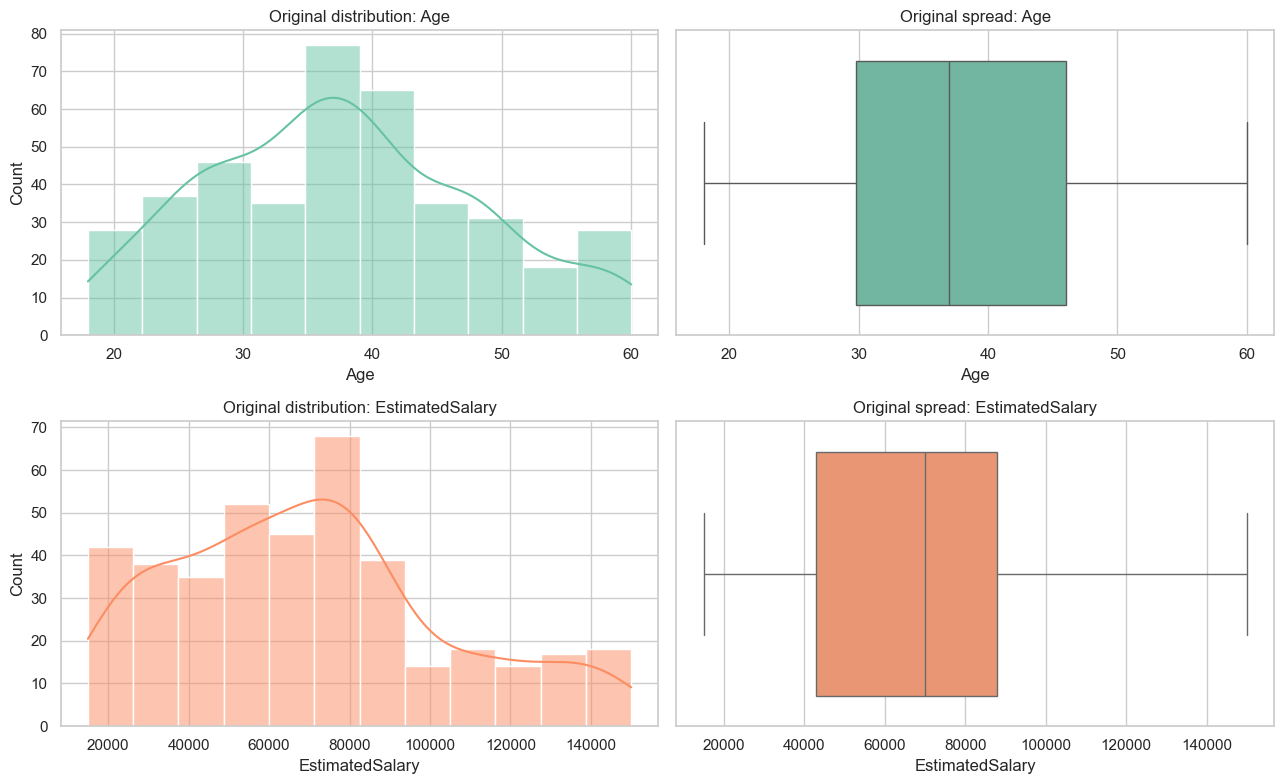

In [4]:
numeric_features = ["Age", "EstimatedSalary"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, col in enumerate(numeric_features):
    sns.histplot(data=df, x=col, kde=True, ax=axes[row, 0], color=sns.color_palette()[row])
    axes[row, 0].set_title(f"Original distribution: {col}")
    sns.boxplot(data=df, x=col, ax=axes[row, 1], color=sns.color_palette()[row])
    axes[row, 1].set_title(f"Original spread: {col}")
plt.tight_layout()
plt.show()

## 4. What min–max normalization does

For a value $x$ in a feature, min–max scaling is

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

The smallest training value maps to 0 and the largest training value maps to 1. Values between them map proportionally. The transformation preserves the ordering of values, but changes units. A constant feature (where max = min) has no range to rescale.

### Why split before fitting the scaler?

We first separate a held-out test set, then **fit** the scaler only on training data. That prevents information from the test set influencing training-time preprocessing. We reuse the same fitted scaler to transform both sets. With this correct workflow, a test value can fall slightly below 0 or above 1 if it lies beyond the training range; clipping is optional and should be a deliberate modeling choice.

## 5. Prepare predictors and target

We retain `Gender` as a categorical input conceptually, but this notebook focuses on numeric feature normalization. The modeling-ready feature table below uses just `Age` and `EstimatedSalary`; users who want to include gender can encode it separately (for example, one-hot encoding) and generally should not min–max scale the resulting binary indicator. The target and ID are kept separate.

In [5]:
X = df[numeric_features].copy()
y = df["Purchased"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Training feature rows:", len(X_train))
print("Test feature rows:", len(X_test))
print("Training purchase rate:", round(y_train.mean(), 3))
print("Test purchase rate:", round(y_test.mean(), 3))

Training feature rows: 300
Test feature rows: 100
Training purchase rate: 0.357
Test purchase rate: 0.36


## 6. Fit on training data, transform both partitions

`fit` learns a separate minimum and maximum for each column from `X_train`. `transform` applies those stored values without relearning them. We wrap the result in DataFrames to retain column names and row indexes for easier inspection.

In [6]:
scaler = MinMaxScaler(feature_range=(0, 1))
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=numeric_features, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=numeric_features, index=X_test.index
)

scaler_parameters = pd.DataFrame(
    {"training_min": scaler.data_min_, "training_max": scaler.data_max_,
     "scale_factor": scaler.scale_}, index=numeric_features
)
display(scaler_parameters)
display(X_train_scaled.head())

,training_min,training_max,scale_factor
Age,18.0,60.0,0.023810
EstimatedSalary,15000.0,150000.0,0.000007


,Age,EstimatedSalary
352,0.571429,0.555556
311,0.500000,0.600000
85,0.309524,0.762963
179,0.309524,0.140741
235,0.666667,0.474074


## 7. Verify the result

Training minima should be 0 and maxima should be 1 for non-constant columns. Test extrema are reported separately: unlike a scaler fitted to the full dataset, they are not guaranteed to be exactly 0 and 1, and may extend beyond the interval if test observations exceed the training range.

In [7]:
print("Training scaled minima:")
display(X_train_scaled.min().to_frame("min"))
print("Training scaled maxima:")
display(X_train_scaled.max().to_frame("max"))
print("Test scaled range:")
display(pd.DataFrame({"min": X_test_scaled.min(), "max": X_test_scaled.max()}))

assert np.allclose(X_train_scaled.min().values, 0.0)
assert np.allclose(X_train_scaled.max().values, 1.0)
print("Training range checks passed.")

Training scaled minima:


,min
Age,0.0
EstimatedSalary,0.0


Training scaled maxima:


,max
Age,1.0
EstimatedSalary,1.0


Test scaled range:


,min,max
Age,0.0,1.0
EstimatedSalary,0.0,1.0


Training range checks passed.


## 8. Compare original and normalized values

The following plot uses the training partition only. Separate panels preserve each feature's distribution shape while making the changed range visible. A scatter plot then shows how scaling changes axis units without changing the relative positions or ordering of observations.

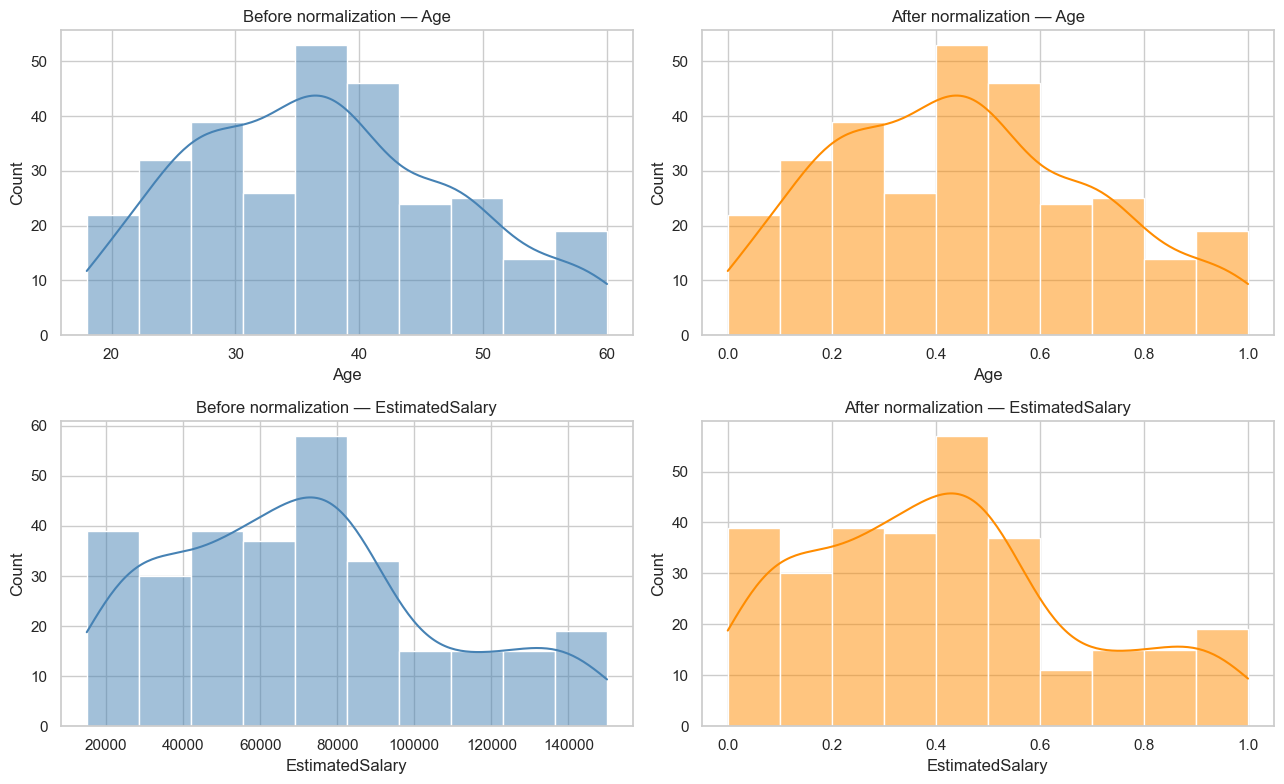

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, col in enumerate(numeric_features):
    sns.histplot(X_train[col], kde=True, ax=axes[row, 0], color="steelblue")
    axes[row, 0].set_title(f"Before normalization — {col}")
    sns.histplot(X_train_scaled[col], kde=True, ax=axes[row, 1], color="darkorange")
    axes[row, 1].set_title(f"After normalization — {col}")
plt.tight_layout()
plt.show()

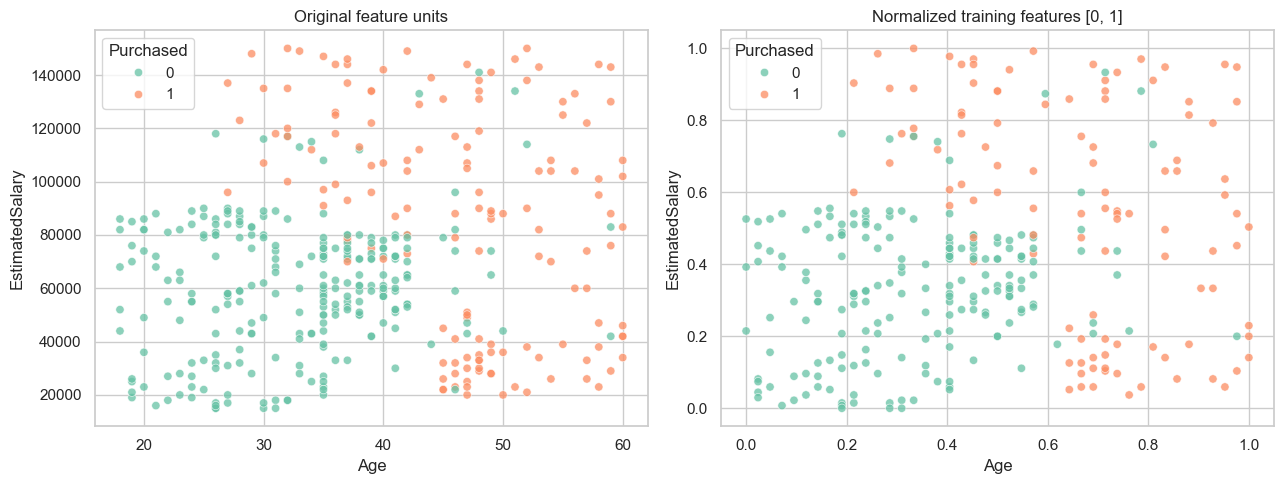

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="Age", y="EstimatedSalary", hue="Purchased", alpha=0.75, ax=axes[0])
axes[0].set_title("Original feature units")
train_plot = X_train_scaled.join(y_train.rename("Purchased"))
sns.scatterplot(data=train_plot, x="Age", y="EstimatedSalary", hue="Purchased", alpha=0.75, ax=axes[1])
axes[1].set_title("Normalized training features [0, 1]")
plt.tight_layout()
plt.show()

## 9. Inspect individual examples

This side-by-side table helps connect the formula to actual rows. The normalized columns are derived from the training extrema shown above; rows in this sample are selected from the training partition.

In [10]:
comparison = pd.concat(
    [X_train.head(10).add_suffix("_original"), X_train_scaled.head(10).add_suffix("_normalized"), y_train.head(10).rename("Purchased")],
    axis=1
)
display(comparison)

,Age_original,EstimatedSalary_original,Age_normalized,EstimatedSalary_normalized,Purchased
352,42,90000,0.571429,0.555556,1
311,39,96000,0.500000,0.600000,1
85,31,118000,0.309524,0.762963,1
179,31,34000,0.309524,0.140741,0
235,46,79000,0.666667,0.474074,1
145,24,89000,0.142857,0.548148,0
72,20,23000,0.047619,0.059259,0
253,37,146000,0.452381,0.970370,1
148,29,61000,0.261905,0.340741,0
280,59,88000,0.976190,0.540741,1


## 10. Interpretation, limitations, and next steps

- Normalization puts the two numeric inputs onto a shared, unitless range, which is often useful for distance-based methods such as k-nearest neighbors and for optimization-sensitive models.
- It does not guarantee better performance for every model. Tree-based models often need little or no feature scaling.
- It does not normalize the target, encode categories, remove outliers, or make data Gaussian.
- Min–max scaling is sensitive to extreme values because the observed minimum and maximum determine the mapping. If outliers are a concern, investigate them and consider robust scaling based on a modeling goal.
- Keep the fitted scaler with the trained model and apply that same scaler to future inputs. In a production or cross-validation workflow, use a scikit-learn `Pipeline` so preprocessing is fit independently inside each training fold.
- `User ID` was excluded because identifiers are not meaningful measurements. `Purchased` was excluded to prevent target leakage. `Gender` needs categorical encoding if included in a model; do that as a separate preprocessing step.

### Optional manual calculation

The next cell calculates the training-set formula directly for the first row and compares it with scikit-learn. This is a transparent arithmetic cross-check, not a replacement for a reusable fitted transformer.

In [11]:
first_row = X_train.iloc[0]
manual = (first_row - X_train.min()) / (X_train.max() - X_train.min())
scikit_value = X_train_scaled.iloc[0]
display(pd.DataFrame({"manual_formula": manual, "MinMaxScaler": scikit_value}))
assert np.allclose(manual.values, scikit_value.values)
print("Manual formula matches MinMaxScaler for this training row.")

,manual_formula,MinMaxScaler
Age,0.571429,0.571429
EstimatedSalary,0.555556,0.555556


Manual formula matches MinMaxScaler for this training row.


## Summary

This analysis loaded and checked the data, visualized the raw numeric features, split data before fitting preprocessing, applied training-only min–max parameters to both train and test sets, and verified the transformed ranges. The resulting `X_train_scaled` and `X_test_scaled` are ready to be passed to a model alongside `y_train` and `y_test`.